### Week 2: **Exploratory Data Analysis: NextGenLearners Applicant Insights**
**Goal of this week:** Explore the cleaned applicant data, find patterns, and explain them in plain English.

### Day 1: **Load, check, and plan**
**Today:** Reload the cleaned data, confirm it is trustworthy, and decide which questions to answer.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("applicants_cleaned.csv", parse_dates=["Application Date"], dayfirst=True)

In [2]:
df.info()              # Checks column types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    71 non-null     str           
 1   Email             71 non-null     str           
 2   Phone             71 non-null     int64         
 3   Domain Applied    71 non-null     str           
 4   University        71 non-null     str           
 5   Application Date  69 non-null     datetime64[us]
 6   Status            71 non-null     str           
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 4.0 KB


In [3]:
print(df.shape)                # shape gives no of rows and columns      

(71, 7)


In [4]:
print(df.isnull().sum())                # counts missing values per column

Applicant Name      0
Email               0
Phone               0
Domain Applied      0
University          0
Application Date    2
Status              0
dtype: int64


   **Note:** 2 of the 71 applications have no recorded date, so this chart shows 69 applications. All 71 are included in the other charts.

In [5]:
df["Application Date"].describe()            # Gives the count, the earliest and latest dates, and the middle dates

count                            69
mean     2026-05-18 15:39:07.826087
min             2026-01-17 00:00:00
25%             2026-03-18 00:00:00
50%             2026-05-15 00:00:00
75%             2026-07-13 00:00:00
max             2026-09-30 00:00:00
Name: Application Date, dtype: object

### Analysis Plan
These are the 5 questions I will answer, one per section below.
1. Which domain received the most applications?
2. How did applications trend over time?
3. What is the acceptance rate, overall and per domain?
4. Which universities sent the most applicants?
5. Bonus: *(my own question, e.g. applications by day of the week)*

### Day 2: **Domain Popularity**
**Today:** Find out which domains attract the most applicants, using counts and a bar chart.

### Question 1: Which domain received the most applications?
**Goal:** Rank the domains by number of applications, so we can see where interest is highest and lowest.

In [6]:
domain_counts = df["Domain Applied"].value_counts()
print(domain_counts)

Domain Applied
Graphic Design            20
Digital Marketing         16
Data Science              14
Mobile App Development    12
Web Development            9
Name: count, dtype: int64


Count how many applications each domain received.

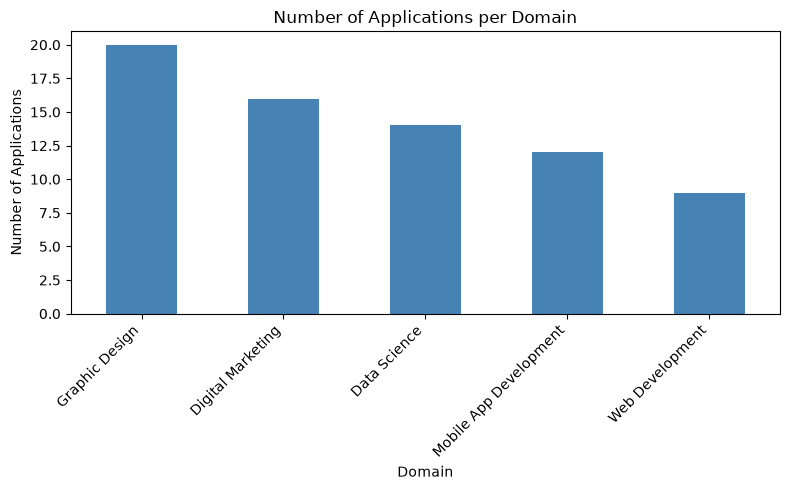

In [7]:
plt.figure(figsize=(8, 5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Takeaway:** Graphic Design received the highest number of applications (20), more than double the lowest domain, Web Development (9).

### Day 3: **Application trend over time**
**Today:** Group applications by month and draw a line chart to see how interest changed.

### Question 2: How did applications trend over time?
**Goal:** See which months were busiest and quietest, and whether interest rose or fell.

In [8]:
df["Application Month"] = df["Application Date"].dt.to_period("M")
monthly_trend = df.groupby("Application Month").size()
print(monthly_trend)

Application Month
2026-01     2
2026-02    11
2026-03    12
2026-04     8
2026-05    12
2026-06     6
2026-07     4
2026-08     6
2026-09     8
Freq: M, dtype: int64


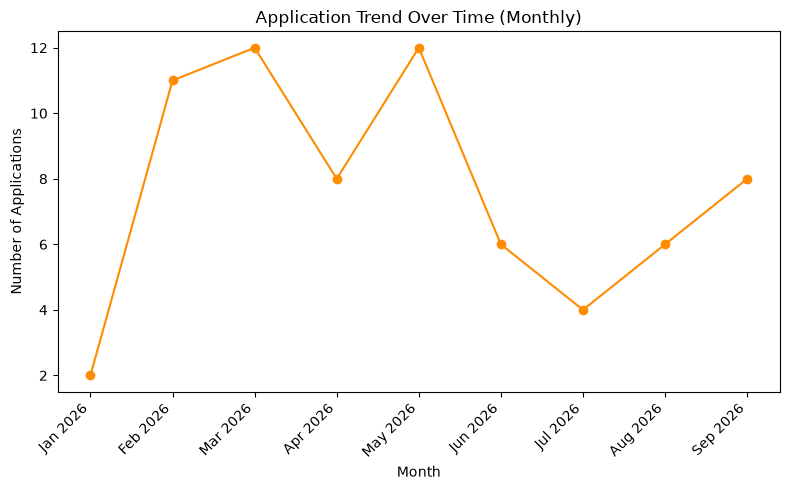

In [9]:
plt.figure(figsize=(8, 5))
monthly_trend.index = monthly_trend.index.strftime("%b %Y")
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Note:** 2 of the 71 applications have no recorded date, so this chart shows 69 applications. All 71 are included in the other charts.

**Takeaway:** Applications peaked in March and May (12 each), with February close behind (11). After May they fell to a low of 4 in July, then partly recovered to 8 in September. January's count of 2 is low partly because the data only starts on 17 January.

### Day 4: **Acceptance rate**
**Today:** Count application statuses overall and per domain, convert counts to percentages, and chart them.

### Question 3: What is the acceptance rate, overall and per domain?
**Goal:** Count the statuses overall, break them down by domain with a pivot table, convert to percentages, and chart the results.

**Part A:** Overall status

Count how many applicants have each status.

In [10]:
status_counts = df["Status"].value_counts()
print(status_counts)

Status
Under Review    34
Selected        23
Rejected        14
Name: count, dtype: int64


**Part B:** Pivot table

Build a grid of domain vs. status, showing how many applicants fall in each combination.

In [11]:
status_by_domain = pd.pivot_table(df, index="Domain Applied", columns="Status", values="Applicant Name", aggfunc="count", fill_value=0)
print(status_by_domain)

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Data Science                   3         5             6
Digital Marketing              3         4             9
Graphic Design                 6         6             8
Mobile App Development         2         3             7
Web Development                0         5             4


**Part C:** Percentages

Convert counts to percentages of each domain's total, so domains of different sizes can be compared fairly.

In [12]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0)*100
print(status_by_domain_pct.round(1))

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Data Science                21.4      35.7          42.9
Digital Marketing           18.8      25.0          56.2
Graphic Design              30.0      30.0          40.0
Mobile App Development      16.7      25.0          58.3
Web Development              0.0      55.6          44.4


**Part D:** Charts

Pie chart: share of each status across all applicants.

In [13]:
status_colors = {"Rejected": "#2ca02c", "Selected": "#ff7f0e", "Under Review": "#1f77b4"}

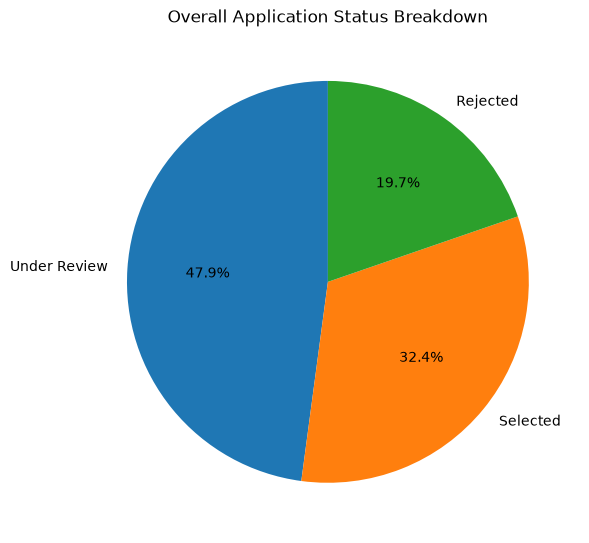

In [14]:
plt.figure(figsize=(6, 6))
status_counts.plot(kind="pie", colors=[status_colors[s] for s in status_counts.index], autopct="%1.1f%%", startangle=90)
plt.title("Overall Application Status Breakdown")
plt.ylabel("")
plt.tight_layout()
plt.show()

47.9% of applicants are still under review, 32.4% have been selected and 19.7% rejected.

Grouped bar chart: status counts for each domain.

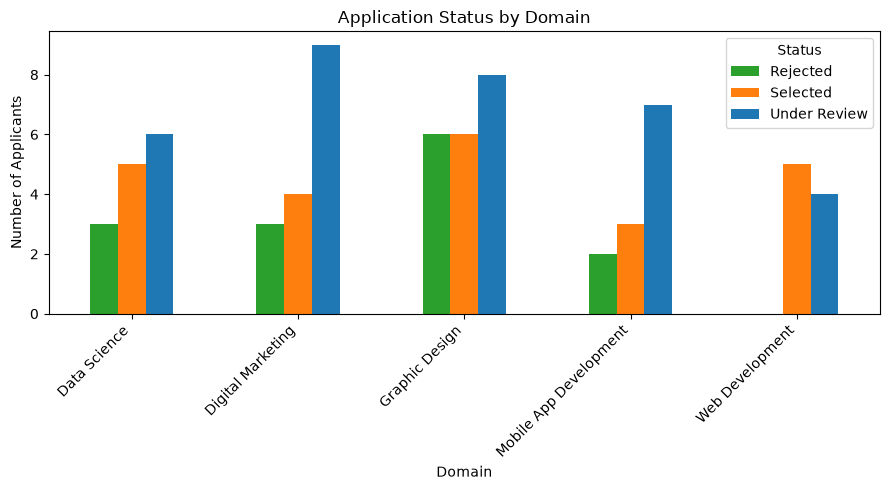

In [15]:
status_by_domain.plot(kind="bar", color=[status_colors[s] for s in status_by_domain.columns], figsize=(9, 5))
plt.title("Application Status by Domain")
plt.xlabel("Domain")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Status")
plt.tight_layout()
plt.show()

Under Review is the largest group in four of the five domains. Web Development has no rejections.

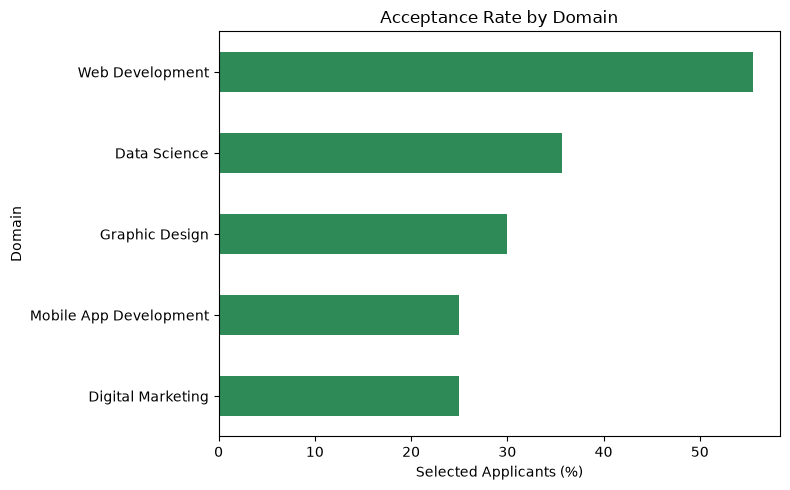

In [16]:
acceptance_rate = status_by_domain_pct["Selected"].sort_values()
plt.figure(figsize=(8, 5))
acceptance_rate.plot(kind="barh", color="seagreen")
plt.title("Acceptance Rate by Domain")
plt.xlabel("Selected Applicants (%)")
plt.ylabel("Domain")
plt.tight_layout()
plt.show()

**Takeaway:** Overall, 32.4% of applicants (23 of 71) were selected. Web Development had the highest acceptance rate (55.6%, 5 of 9 applicants), while Mobile App Development (25%, 3 of 12) and Digital Marketing (25%, 4 of 16) had the lowest.

**Note:** 47.9% of applicants (34 of 71) are still "Under Review", so these rates will change once those decisions are made. Each domain has only 9 to 20 applicants, so a single decision can shift a rate noticeably.

### Day 5: **Top universities**

**Today:** Find which universities sent the most applicants, using counts and a horizontal bar chart.

### Question 4: Which universities sent the most applicants?
**Goal:** Rank the universities by number of applicants, so future outreach can focus on the places that send the most people.

**Part A:** Check the university names first

Check how many different universities there are and whether any names are spelled in more than one way.

In [17]:
print(df["University"].nunique())
print(sorted(df["University"].unique()))

8
['COMSATS University', 'FAST NUCES', 'IBA Karachi', 'LUMS', 'NED University', 'NUST', 'Not Specified', 'University of Karachi']


**Part B:** The counts

Count the applicants from each university and keep the top 10.


In [18]:
top_universities = df["University"].value_counts().head(10)
print(top_universities)

University
University of Karachi    15
NED University           14
FAST NUCES               12
COMSATS University       11
NUST                      7
Not Specified             5
LUMS                      4
IBA Karachi               3
Name: count, dtype: int64


**Part C:** Share of the top 3

Work out what share of all applicants come from the top 3 universities.

In [19]:
top3_count = top_universities.head(3).sum()
top3_share = top3_count/len(df)*100
print(f"Top 3 Universities: {top3_count} of {len(df)} applicants ({top3_share:.1f}%)")

Top 3 Universities: 41 of 71 applicants (57.7%)


**Part D:** The chart

Plot the top universities as a horizontal bar chart, which keeps long university names readable.

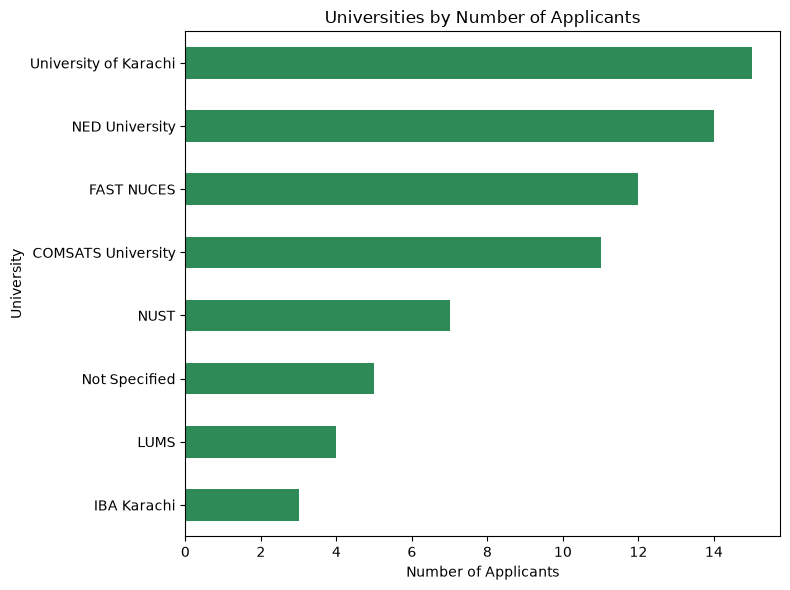

In [20]:
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind="barh", color="seagreen")
plt.title("Universities by Number of Applicants")
plt.xlabel("Number of Applicants")
plt.ylabel("University")
plt.tight_layout()
plt.show()

**Takeaway:** 
University of Karachi sent the most applicants (15 of 71), followed by NED University (14) and FAST NUCES (12). The top 3 universities together account for 57.7% of all applications.

**Note:** 5 applicants (7%) listed no university ("Not Specified"), so they are not attributed to any institution.

### Day 6: **Bonus Question and Key Insights**
**Today:** Answer one question of my own choosing, then summarise everything I found for a non-technical reader.

### Question 5 (Bonus): On which days of the week do people apply?
**Goal:** See whether applications cluster on weekdays or weekends, which could help decide when to post reminders or announcements.
**Why I chose this:** the data has exact application dates, so the day of the week is a free extra pattern to check, and it is something an outreach team can act on.

**Part A:** Count by weekday

Convert each date to its day name and count applications per day, in calendar order.

In [21]:
df["Weekday"] = df["Application Date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = df["Weekday"].value_counts().reindex(weekday_order, fill_value=0)
print(weekday_counts)
print("Total with a date:", weekday_counts.sum())

Weekday
Monday        8
Tuesday       6
Wednesday     6
Thursday     13
Friday       12
Saturday     15
Sunday        9
Name: count, dtype: int64
Total with a date: 69


**Part B:** Chart

Plot applications per weekday as a bar chart.

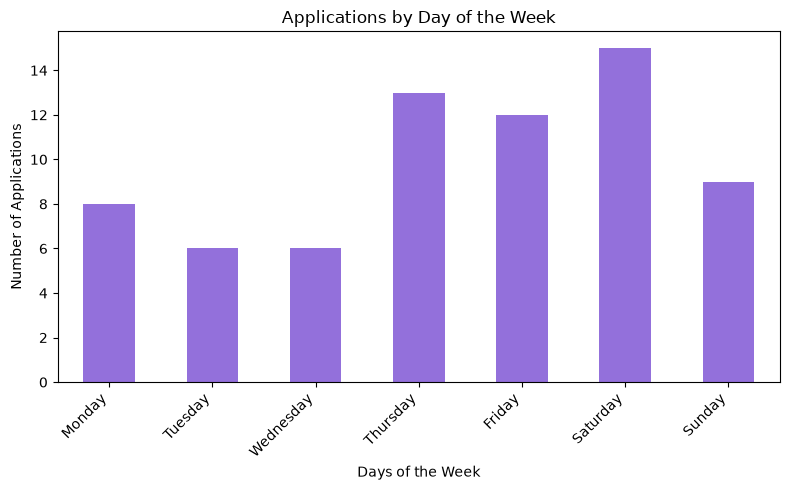

In [22]:
plt.figure(figsize=(8, 5))
weekday_counts.plot(kind="bar", color="mediumpurple")
plt.title("Applications by Day of the Week")
plt.xlabel("Days of the Week")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Part C:** Weekend Share

In [23]:
weekend_count = weekday_counts[["Saturday", "Sunday"]].sum()
weekend_share = weekend_count / weekday_counts.sum() * 100
print(f"Weekend applications: {weekend_count} of {weekday_counts.sum()} ({weekend_share:.1f}%)")

Weekend applications: 24 of 69 (34.8%)


**Takeaway:** Saturday was the busiest day for applications (15), and Tuesday and Wednesday were the quietest (6). Weekends account for 34.8% of applications, compared with about 29% if applications were spread evenly.

**Note:** 2 applications have no date, so this chart shows 69 applications.

## Key Insights

- **Graphic Design is the most popular domain**, with 20 of 71 applications, more than double Web Development (9). Digital Marketing (16) and Data Science (14) come next.
- **Applications peaked in March and May (12 each) and dipped to 4 in July**, then recovered to 8 in September. Outreach could be timed around the stronger months.
- **Web Development has the highest acceptance rate so far (55.6%, 5 of 9)**, compared with 25% for Mobile App Development (3 of 12) and Digital Marketing (4 of 16). Nearly half of all applicants (47.9%) are still under review, so these rates will change.
- **Three universities send most applicants:** University of Karachi (15), NED University (14) and FAST NUCES (12) together account for 57.7% of all applications. Outreach could focus on them, or on reaching other universities.
- **Applications cluster at the end of the week:** Thursday to Saturday bring in 40 of 69 dated applications (58%), with Saturday the busiest day (15) and Tuesday and Wednesday the quietest (6 each). Reminders or announcements could be posted just before Thursday.
